# TP2 — Diseño equirizado (Parks-McClellan) vs. ventaneo de Kaiser

En `disenio_filtros_tp2.ipynb` vimos que pasaaltos/pasabanda/elimina banda
salen caros en taps porque tienen el corte pegado a continua, lo que obliga
a una banda de transición angosta — y la fórmula de Kaiser dice que eso
cuesta taps.

Ese análisis asumía una sola cosa fija que en realidad también es una
decisión de diseño: **el método de ventaneo**. Este notebook prueba un
método distinto, **equirizado (algoritmo de Parks-McClellan / intercambio
de Remez)**, para los mismos `Fc`/`Fs`/`Astop`/`df` — sin tocar ninguno de
esos cuatro parámetros ni cambiar de filtro.

`disenar_fir_equiripple`, la función nueva, vive en `disenio_filtros_tp2.py`
junto a `disenar_fir_kaiser` — **no se tocó ni se sacó nada de Kaiser**,
quedan las dos disponibles.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt

import disenio_filtros_tp2 as fir
print('Módulo cargado desde:', fir.__file__)

Módulo cargado desde: /home/wanda/Documentos/Facultad/DSP/DSP---TPs/TP2/filtros/disenio_filtros_tp2.py


## 1. Por qué el ventaneo no es el método "óptimo"

Kaiser arma el filtro multiplicando el sinc ideal por una ventana — es
simple y tiene fórmulas cerradas para `beta` y `N`, pero **no busca
activamente el filtro de menor orden posible**: reparte el error de forma
pareja porque así es la ventana, no porque sea matemáticamente lo mejor que
se puede hacer para ese orden.

El algoritmo de **Parks-McClellan** (que usa el método de intercambio de
Remez) plantea el problema al revés: para un orden `N` dado, busca
explícitamente los coeficientes que **minimizan el error máximo** entre la
respuesta real y la ideal, banda por banda (en el sentido de Chebyshev /
minimax). El resultado característico es que el rizado queda **parejo**
dentro de cada banda — ningún punto de la banda de paso o de rechazo está
"mejor" que los demás, todo el margen disponible se usa al límite. Esa es
la diferencia de fondo: Kaiser deja margen sin usar, Remez no.

La consecuencia práctica: para la misma especificación (mismos bordes de
banda, mismo `Astop`), un diseño equirizado casi siempre necesita **menos
taps** que uno por ventaneo de Kaiser — a veces bastante menos, como vamos
a ver.

## 2. La función nueva

Misma firma y mismo dict de salida que `disenar_fir_kaiser`, así que se
puede usar con las mismas `atenuacion_lograda`/`graficar`/etc.:

```python
disenar_fir_equiripple(ftype, cutoff, astop_db, fs, df, numtaps=None,
                        ripple_paso_db=0.5)
```

La única diferencia de parámetros: en vez de no tener nada que elegir sobre
la banda de paso (Kaiser reparte `beta` automático), acá hay que decir
cuánto rizado se tolera ahí (`ripple_paso_db`) — Remez lo necesita para
saber cómo repartir el error entre bandas. No lo fija la consigna, igual
que pasaba con `df` en Kaiser.

In [2]:
r = fir.disenar_fir_equiripple('highpass', cutoff=35, astop_db=30, fs=8000, df=50)
print(f"numtaps={r['numtaps']}  Astop Q15={r['astop_q']:.1f} dB  ripple={r['ripple_q']:.2f} dB")

numtaps=150  Astop Q15=30.2 dB  ripple=1.08 dB


## 3. Un bug real que apareció al implementarlo (y cómo se resolvió)

Vale la pena dejarlo documentado porque no es obvio. `normalizar_pico_0db`
(que ya usaba Kaiser) solo garantiza que la **ganancia en frecuencia** de
la banda de paso sea 0 dB. Con Kaiser eso alcanza para que cada coeficiente
individual del filtro quede chico (`|h[n]| < 1`), porque un sinc ventaneado
tiene esa forma.

Un diseño equirizado no tiene esa garantía: para algunos casos (pasabanda
en particular) Remez devolvió coeficientes individuales de magnitud ~70,
aunque la ganancia *en frecuencia* seguía dando correctamente 0 dB — varios
taps grandes se cancelan entre sí al sumarse. Al cuantizar a Q15 (que
asume `|h[n]| < 1` para cada coeficiente, no para la respuesta en
frecuencia), esos taps gigantes se saturaban todos al mismo valor
(±32767), y el filtro quedaba roto (`Astop` medido daba **negativo**, peor
que no filtrar nada).

El arreglo quedó en `cuantizar_q15`: si algún coeficiente individual supera
1 en magnitud, se reescala *antes* de cuantizar. Con Kaiser nunca dispara
(nunca hizo falta), así que no le cambió nada.

In [3]:
# Demostracion: el caso que disparaba el bug (pasabanda, cuyos taps
# individuales pueden superar 1 en magnitud antes de la correccion)
r = fir.disenar_fir_equiripple('bandpass', cutoff=[35, 3500], astop_db=30, fs=8000, df=[50, 400])
print(f"numtaps={r['numtaps']}  Astop Q15={r['astop_q']:.1f} dB  (con el arreglo, da bien)")

numtaps=110  Astop Q15=35.4 dB  (con el arreglo, da bien)


## 4. Comparación completa: Kaiser vs. Equirizado, los 20 casos

Mismos `Fc`/`Fr`/`Bw`/`Astop`/`df` que en `disenio_filtros_tp2.ipynb` (y
que `main()` del script), para los 4 filtros en las 5 frecuencias de
muestreo del TP. Tarda unos minutos — elimina banda a 44-48 kHz es el caso
más pesado para Remez.

In [4]:
%%time
fs_label = ['8k', '16k', '22k', '44k', '48k']
fs_list = [8000, 16000, 22000, 44000, 48000]

filtros = [
    dict(key='lp', desc='Pasa bajos',    ftype='lowpass',
         cutoff=3600,                               df=400,        astop=30),
    dict(key='hp', desc='Pasa altos',    ftype='highpass',
         cutoff=35,                                 df=50,         astop=30),
    dict(key='bp', desc='Pasa banda',    ftype='bandpass',
         cutoff=[35, 3500],                         df=[50, 400],  astop=30),
    dict(key='bs', desc='Elimina banda', ftype='bandstop',
         cutoff=fir.cutoff_bandstop_fr_bw(fr=50, bw=15, df=20),
         df=20, astop=25),
]

res_kaiser, res_equi = {}, {}
for F in filtros:
    for fsl, fs in zip(fs_label, fs_list):
        res_kaiser[(F['key'], fsl)] = fir.disenar_fir_kaiser(F['ftype'], F['cutoff'], F['astop'], fs, F['df'])
        res_equi[(F['key'], fsl)]   = fir.disenar_fir_equiripple(F['ftype'], F['cutoff'], F['astop'], fs, F['df'])
print('Listo:', len(res_kaiser), '+', len(res_equi), 'diseños')

Listo: 20 + 20 diseños
CPU times: user 2min 30s, sys: 42 s, total: 3min 12s
Wall time: 3min 12s


In [5]:
print(f"{'filt':<4s} {'Fs':>6s} {'Kaiser':>8s} {'Equirip.':>9s} {'reduccion':>10s} {'Astop K / E':>14s}")
for F in filtros:
    for fsl in fs_label:
        rk, re = res_kaiser[(F['key'], fsl)], res_equi[(F['key'], fsl)]
        red = 100 * (1 - re['numtaps'] / rk['numtaps'])
        print(f"{F['key']:<4s} {fsl:>6s} {rk['numtaps']:>8d} {re['numtaps']:>9d} {red:>9.0f}% "
              f"{rk['astop_q']:>6.1f} / {re['astop_q']:<6.1f}")

filt     Fs   Kaiser  Equirip.  reduccion    Astop K / E
lp       8k       34        28        18%   31.6 / 31.6  
lp      16k       64        48        25%   30.5 / 30.1  
lp      22k       86        66        23%   30.1 / 30.5  
lp      44k      170       128        25%   30.2 / 30.1  
lp      48k      186       140        25%   30.3 / 30.2  
hp       8k      344       150        56%   30.0 / 30.2  
hp      16k      688       296        57%   30.0 / 30.1  
hp      22k      948       408        57%   30.2 / 30.0  
hp      44k     1890       806        57%   30.0 / 30.0  
hp      48k     2052       954        54%   30.0 / 32.1  
bp       8k      346       110        68%   30.7 / 35.4  
bp      16k      690       250        64%   30.2 / 45.5  
bp      22k      946       342        64%   30.2 / 37.5  
bp      44k     1890       682        64%   30.1 / 30.9  
bp      48k     2064       746        64%   30.0 / 31.2  
bs       8k      646       462        28%   25.2 / 25.0  
bs      16k    

La reducción es más chica en pasa bajos (ya era barato con Kaiser,
hay poco para optimizar) y más grande en pasabanda/pasaaltos — justo los
casos que más taps necesitaban. Sigue sin ser magia: elimina banda a 44-48
kHz sigue siendo caro, solo que un poco menos.

## 5. Respuesta en frecuencia, Kaiser vs. Equirizado

Un gráfico por filtro, Kaiser en azul y equirizado en magenta superpuestos,
un subplot por Fs. Fijate en la banda de rechazo: Kaiser decae suave hacia
los costados (el rizado de la ventana), equirizado oscila parejo pegado al
piso de `Astop` — esa es la firma visual del diseño minimax.

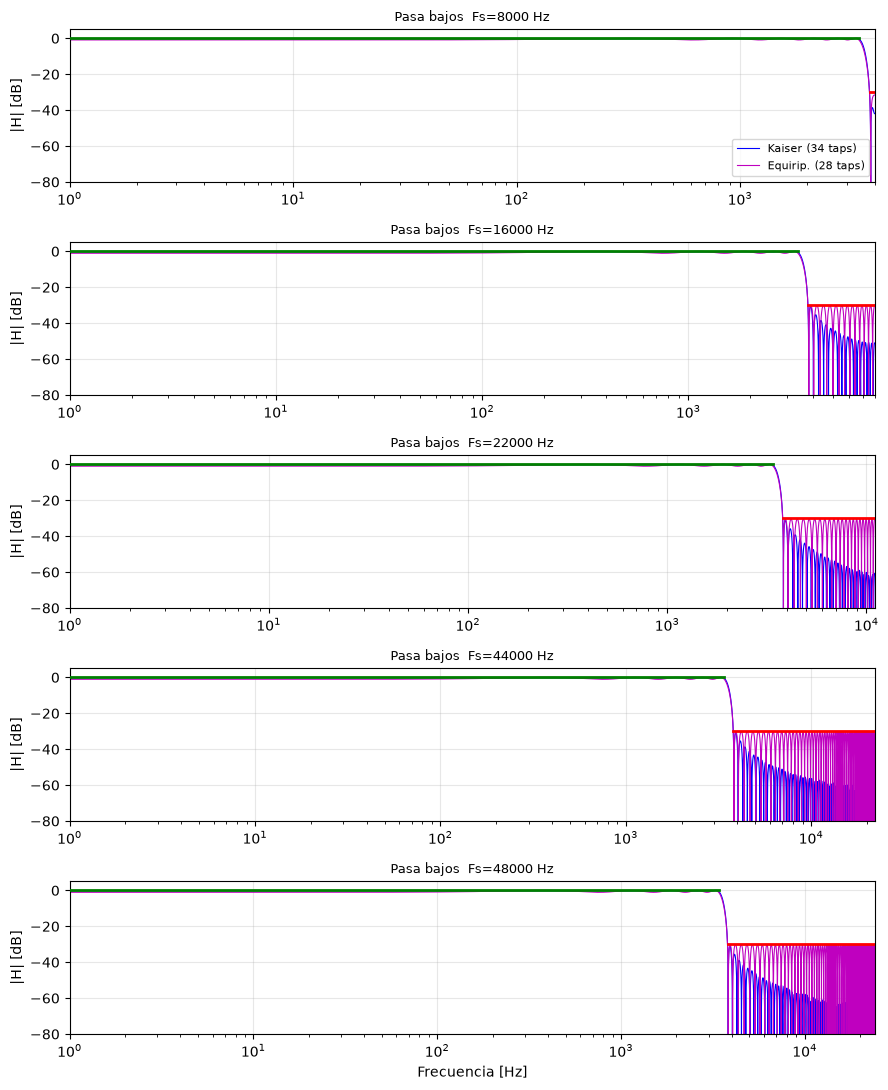

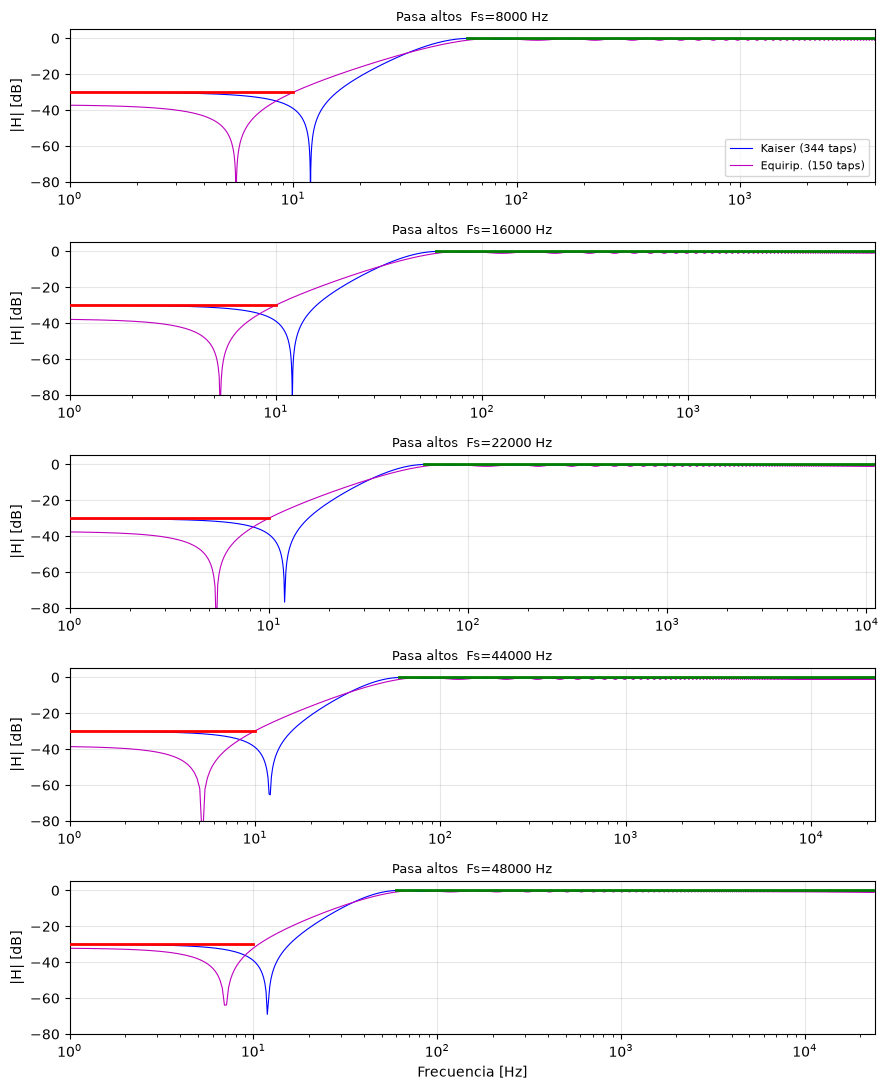

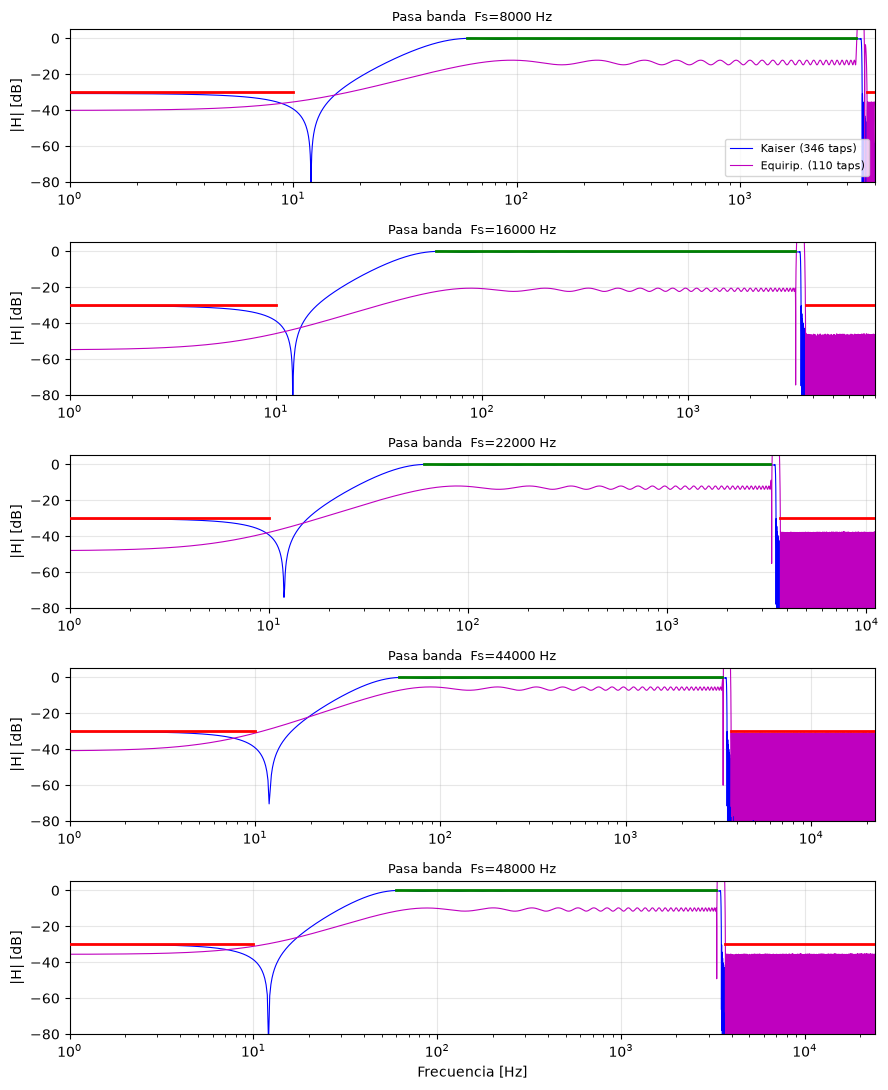

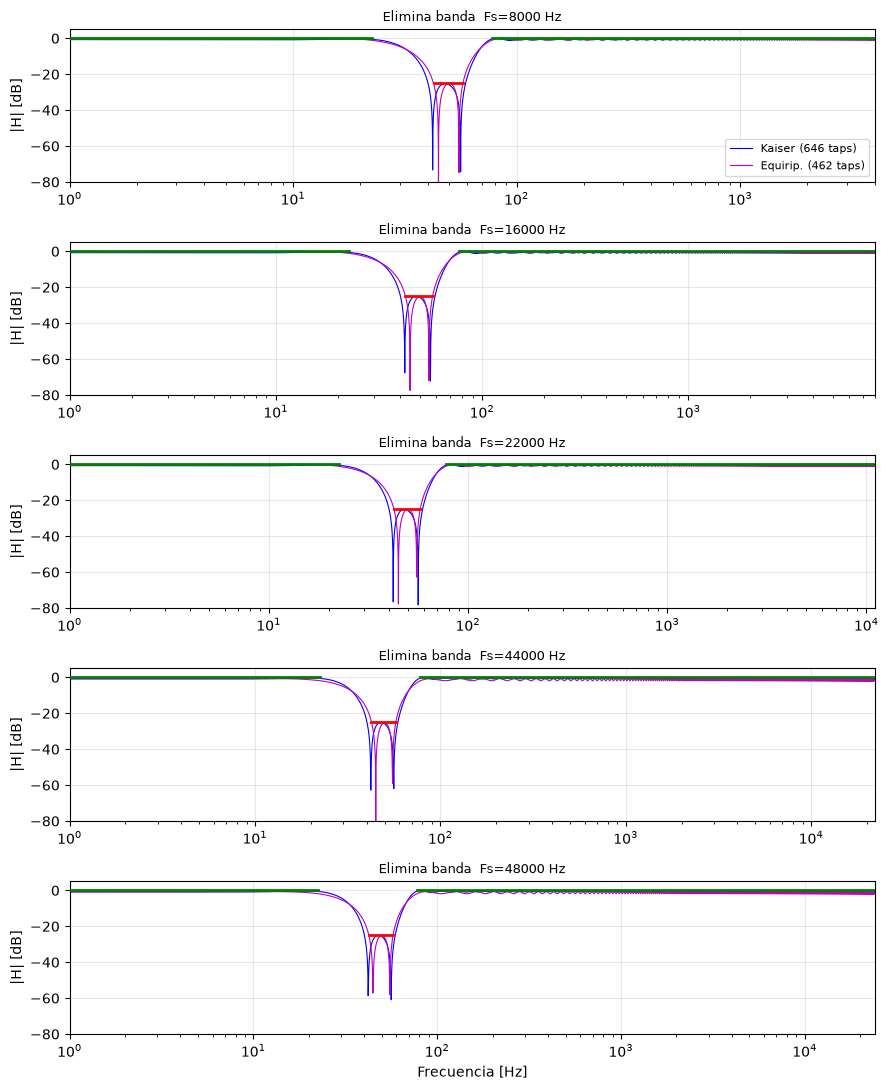

In [6]:
for F in filtros:
    n = len(fs_label)
    fig, axes = plt.subplots(n, 1, figsize=(9, 2.2 * n))
    for ax, fsl in zip(axes, fs_label):
        rk, re = res_kaiser[(F['key'], fsl)], res_equi[(F['key'], fsl)]
        fs = rk['fs']
        fK, HK = fir._respuesta_db(rk['q'] / 32768.0, fs, fir.NFFT_DEFAULT)
        fE, HE = fir._respuesta_db(re['q'] / 32768.0, fs, fir.NFFT_DEFAULT)
        ax.semilogx(fK[1:], HK[1:], 'b', linewidth=0.8, label=f"Kaiser ({rk['numtaps']} taps)")
        ax.semilogx(fE[1:], HE[1:], 'm', linewidth=0.8, label=f"Equirip. ({re['numtaps']} taps)")
        zonas, es_paso = fir.zonas_paso_rechazo(fs, rk['cutoff'], rk['df'], rk['pass_zero'])
        for (lo, hi), paso in zip(zonas, es_paso):
            ax.plot([max(lo, 1), hi], [0, 0] if paso else [-F['astop']]*2,
                    'g' if paso else 'r', linewidth=2, zorder=5)
        ax.set_xlim(1, fs/2); ax.set_ylim(-80, 5); ax.grid(alpha=0.3)
        ax.set_ylabel('|H| [dB]')
        ax.set_title(f"{F['desc']}  Fs={fs} Hz", fontsize=9)
    axes[0].legend(loc='lower right', fontsize=8)
    axes[-1].set_xlabel('Frecuencia [Hz]')
    fig.tight_layout()
    plt.show()

## Conclusiones

- Para la misma especificación (`Fc`/`Fr`+`Bw`/`Astop`/`Fs`/`df`), cambiar
  el método de diseño de ventaneo (Kaiser) a equirizado (Parks-McClellan)
  reduce los taps sin tocar ningún parámetro del enunciado ni cambiar de
  filtro — la ganancia es mayor cuanto más "caro" era el filtro con Kaiser
  (pasaaltos/pasabanda), y chica donde ya era barato (pasa bajos).
- No es gratis: Remez no tiene una fórmula cerrada para el orden (hay que
  buscarlo), puede no converger si se arranca con muy pocos taps, y hace
  falta elegir un rizado de paso (`ripple_paso_db`) que la consigna no fija.
- Ojo al cuantizar a Q15 un diseño equirizado: la ganancia en frecuencia
  puede dar bien aunque algún coeficiente individual se pase de 1 en
  magnitud (cancelación entre taps) — `cuantizar_q15` ya lo contempla.
- Ambos métodos quedan disponibles en `disenio_filtros_tp2.py`
  (`disenar_fir_kaiser` y `disenar_fir_equiripple`); `main()` del script
  sigue generando el header con Kaiser, sin cambios.

La celda siguiente regenera `filter_coeffs.h` del proyecto, pero con los
coeficientes **equirizados** (`res_equi`, los de menos taps) en vez de los
de Kaiser — correrla sobreescribe el header real del firmware.

In [ ]:
# Regenera filter_coeffs.h del proyecto con los coeficientes EQUIRIZADOS
# (res_equi, calculados arriba) en vez de los de Kaiser que escribe main()
# del script. Misma ruta que usa main(): relativa a esta carpeta (filtros).
h_path = os.path.join('..', 'MCXN947_Project_TP2', 'source', 'filter_coeffs.h')
fir.exportar_header(res_equi, filtros, fs_label, h_path,
                     metodo='equirizado (Parks-McClellan / Remez)')